# Classification — Logistic Regression on `IsCanceled` (Person 4)

1. Setup & load  
2. Leakage check (done *before* modelling)  
3. Baseline (majority class)  
4. Logistic regression + confusion matrix, precision / recall / F1  
5. Improving recall: class weights & threshold  
6. Interpreting coefficients (odds ratios)  
7. Leakage demonstration  
8. Export for Power BI

## 1. Setup & load

In [2]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, precision_recall_curve)

np.random.seed(42)
os.makedirs("../outputs/figures", exist_ok=True)
path = "../data/processed/hotel_bookings_cleaned.csv"
if not os.path.exists(path): path = "hotel_bookings_cleaned.csv"
df = pd.read_csv(path)
print(df.shape)
print(df["IsCanceled"].value_counts(normalize=True).round(4))

(87396, 37)
IsCanceled
0    0.7251
1    0.2749
Name: proportion, dtype: float64


## 2. Leakage check

**Data leakage** = using information in the features that would not be known at prediction time (or that directly encodes the answer). Our goal: predict, at booking time, whether a booking will be cancelled. So every feature must be available then.

In [3]:
# ReservationStatus is the *outcome* of the booking
print(pd.crosstab(df["ReservationStatus"], df["IsCanceled"]))

IsCanceled             0      1
ReservationStatus              
Canceled               0  23011
Check-Out          63371      0
No-Show                0   1014


`ReservationStatus` = *Canceled* or *No-Show* ⇔ `IsCanceled = 1`, and *Check-Out* ⇔ `IsCanceled = 0`. It is the target in disguise. `ReservationStatusDate` is the date that status was set, so it is also leaked.

**Other columns reviewed:**

| Column | Decision | Why |
|---|---|---|
| `ReservationStatus`, `ReservationStatusDate` | **Drop** | Directly encode the outcome |
| `ArrivalDate` | Drop | Redundant with year/month/week/day (and a datetime) |
| `AssignedRoomType` | Drop | Assigned at/near check-in; cancelled bookings often never get a room assigned, so it is partly post-outcome |
| `BookingChanges` | Keep, with caveat | Can accumulate after booking; flagged as a mild leakage risk |
| `Agent`, `Company` | Drop | Very high-cardinality IDs; little interpretability |
| `Country` | Drop (baseline) | 178 levels; tested separately in Section 5 |
| `LeadTimeBand`, `Season`, `TotalNights`, `TotalGuests` | Drop | Derived from kept columns (avoids redundancy / multicollinearity) |

In [4]:
target = "IsCanceled"
features = ["Hotel","LeadTime","ArrivalDateMonth","ArrivalDateYear","ArrivalDateWeekNumber",
            "StaysInWeekendNights","StaysInWeekNights","Adults","Children","Babies","Meal",
            "MarketSegment","DistributionChannel","IsRepeatedGuest","PreviousCancellations",
            "PreviousBookingsNotCanceled","ReservedRoomType","DepositType","DaysInWaitingList",
            "CustomerType","ADR","RequiredCarParkingSpaces","TotalOfSpecialRequests","BookingChanges"]

X, y = df[features], df[target]
num_cols = [c for c in features if pd.api.types.is_numeric_dtype(X[c])]
cat_cols = [c for c in features if c not in num_cols]
print(len(num_cols), "numeric,", len(cat_cols), "categorical")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, round(y_train.mean(),4), round(y_test.mean(),4))

16 numeric, 8 categorical
(69916, 24) (17480, 24) 0.2749 0.2749


Stratified 80/20 split keeps the ~27.5% cancellation rate in both sets. Scaling and one-hot encoding live inside a `Pipeline`, so they are fitted on the training set only (no leakage from the test set).

## 3. Baseline — always predict the majority class

In [5]:
def evaluate(model, name, Xte=None, yte=None):
    Xte = X_test if Xte is None else Xte; yte = y_test if yte is None else yte
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:,1]
    return {"Model":name, "Accuracy":accuracy_score(yte,pred),
            "Precision":precision_score(yte,pred,zero_division=0),
            "Recall":recall_score(yte,pred), "F1":f1_score(yte,pred),
            "ROC-AUC":roc_auc_score(yte,proba)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
res = [evaluate(dummy, "Baseline (majority class)")]
print(pd.DataFrame(res).round(3))
print(confusion_matrix(y_test, dummy.predict(X_test)))

                       Model  Accuracy  Precision  Recall   F1  ROC-AUC
0  Baseline (majority class)     0.725        0.0     0.0  0.0      0.5
[[12675     0]
 [ 4805     0]]


The baseline reaches ~72.5% accuracy **without detecting a single cancellation** (recall = 0). This is why accuracy alone is misleading on imbalanced data — and why precision/recall/F1 matter.

## 4. Logistic regression

In [6]:
def make_pipe(num, cat, **lr_kwargs):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=2000, **lr_kwargs))])

logit = make_pipe(num_cols, cat_cols).fit(X_train, y_train)
res.append(evaluate(logit, "Logistic Regression"))
print(pd.DataFrame(res).round(3).to_string(index=False))

                    Model  Accuracy  Precision  Recall    F1  ROC-AUC
Baseline (majority class)     0.725       0.00   0.000 0.000    0.500
      Logistic Regression     0.784       0.69   0.388 0.497    0.794


               precision    recall  f1-score   support

Not cancelled      0.801     0.934     0.862     12675
    Cancelled      0.690     0.388     0.497      4805

     accuracy                          0.784     17480
    macro avg      0.746     0.661     0.680     17480
 weighted avg      0.771     0.784     0.762     17480



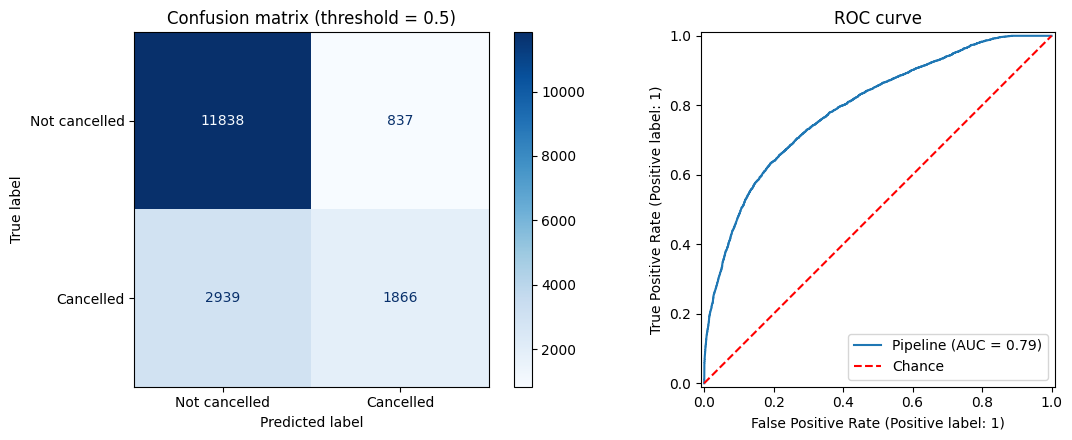

In [7]:
pred = logit.predict(X_test)
print(classification_report(y_test, pred, target_names=["Not cancelled","Cancelled"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not cancelled","Cancelled"],
                                        cmap="Blues", ax=ax[0], values_format="d")
ax[0].set_title("Confusion matrix (threshold = 0.5)")
RocCurveDisplay.from_estimator(logit, X_test, y_test, ax=ax[1])
ax[1].plot([0,1],[0,1],"r--",label="Chance"); ax[1].legend(); ax[1].set_title("ROC curve")
plt.tight_layout(); plt.savefig("../outputs/figures/logit_confusion_roc.png", dpi=120); plt.show()

In [8]:
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Precision = TP/(TP+FP) = {tp/(tp+fp):.3f}")
print(f"Recall    = TP/(TP+FN) = {tp/(tp+fn):.3f}")

TN=11838  FP=837  FN=2939  TP=1866
Precision = TP/(TP+FP) = 0.690
Recall    = TP/(TP+FN) = 0.388


**Reading the results.** Precision ≈ 0.69: when the model flags a booking as a cancellation it is right ~69% of the time. Recall ≈ 0.39: it only catches ~39% of real cancellations. ROC-AUC ≈ 0.79 shows the model ranks risky bookings well, but the default 0.5 threshold is too conservative for a minority class.

## 5. Improving recall

**5a. Class weights** — penalise missing a cancellation more heavily.

In [9]:
logit_bal = make_pipe(num_cols, cat_cols, class_weight="balanced").fit(X_train, y_train)
res.append(evaluate(logit_bal, "Logistic Reg. (balanced)"))

# 5b. Adding Country (high-cardinality) as a test of extra signal
cat_c = cat_cols + ["Country"]
logit_c = make_pipe(num_cols, cat_c).fit(X_train.assign(Country=df.loc[X_train.index,"Country"]), y_train)
Xte_c = X_test.assign(Country=df.loc[X_test.index,"Country"])
res.append(evaluate(logit_c, "Logistic Reg. + Country", Xte_c, y_test))
print(pd.DataFrame(res).round(3).to_string(index=False))

                    Model  Accuracy  Precision  Recall    F1  ROC-AUC
Baseline (majority class)     0.725      0.000   0.000 0.000    0.500
      Logistic Regression     0.784      0.690   0.388 0.497    0.794
 Logistic Reg. (balanced)     0.702      0.473   0.744 0.578    0.794
  Logistic Reg. + Country     0.791      0.675   0.466 0.551    0.834


Balancing trades precision for recall (more cancellations caught, more false alarms). Which is better depends on the business cost: a missed cancellation = an empty room, a false alarm = unnecessary overbooking/outreach. Adding `Country` lifts AUC from 0.79 to 0.83, so a guest's country carries real signal — but with 178 levels it hurts interpretability, so we keep it out of the main model.

In [10]:
# 5c. Threshold tuning on the baseline logistic model
proba = logit.predict_proba(X_test)[:,1]
rows=[]
for t in [0.2,0.3,0.35,0.4,0.5]:
    p=(proba>=t).astype(int)
    rows.append({"Threshold":t,"Precision":precision_score(y_test,p),"Recall":recall_score(y_test,p),"F1":f1_score(y_test,p)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 Threshold  Precision  Recall    F1
      0.20      0.410   0.834 0.550
      0.30      0.495   0.710 0.583
      0.35      0.543   0.642 0.589
      0.40      0.600   0.573 0.586
      0.50      0.690   0.388 0.497


## 6. Interpreting coefficients (odds ratios)

cat__DepositType_Non Refund           8.058
cat__ReservedRoomType_P               5.010
cat__DistributionChannel_Undefined    3.850
num__PreviousCancellations            2.015
cat__MarketSegment_Undefined          1.993
cat__MarketSegment_Complementary      1.579
num__LeadTime                         1.577
cat__CustomerType_Transient           1.540
num__PreviousBookingsNotCanceled      0.592
num__TotalOfSpecialRequests           0.569
cat__ReservedRoomType_F               0.551
cat__DistributionChannel_GDS          0.429
cat__DepositType_Refundable           0.428
cat__MarketSegment_Offline TA/TO      0.289
cat__DepositType_No Deposit           0.193
num__RequiredCarParkingSpaces         0.005
dtype: float64


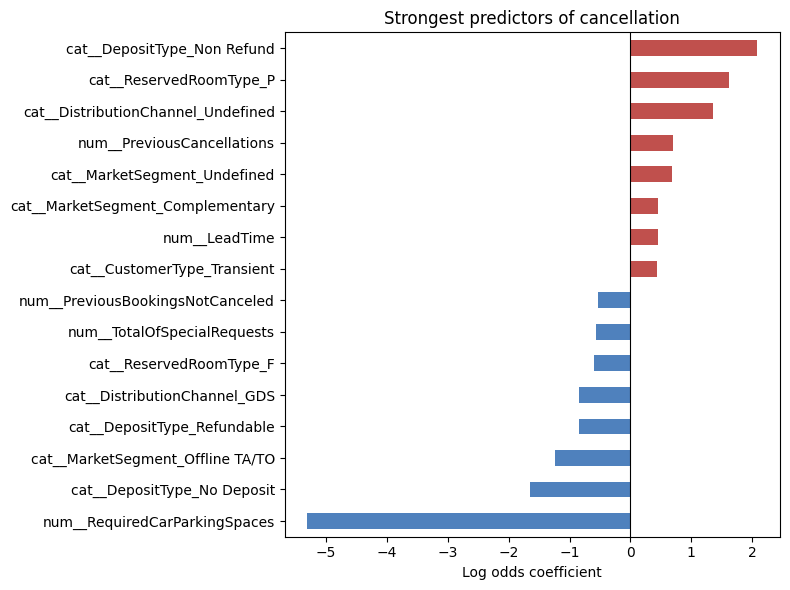

In [11]:
names = logit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logit.named_steps["clf"].coef_[0], index=names)
odds = np.exp(coef).sort_values(ascending=False)
top = pd.concat([odds.head(8), odds.tail(8)])
print(top.round(3))

plt.figure(figsize=(8,6))
(np.log(top)).sort_values().plot.barh(color=["#c0504d" if v>0 else "#4f81bd" for v in np.log(top).sort_values()])
plt.axvline(0,color="k",lw=.8); plt.xlabel("Log odds coefficient"); plt.title("Strongest predictors of cancellation")
plt.tight_layout(); plt.savefig("../outputs/figures/logit_coefficients.png", dpi=120); plt.show()

Numeric features are standardised, so their odds ratio is *per 1 standard deviation*; categorical dummies show the odds for that level (L2-regularised, so levels share information). `DepositType_Non Refund` and `PreviousCancellations` push cancellation odds up strongly; `RequiredCarParkingSpaces` (almost no booking requesting parking cancels), `TotalOfSpecialRequests` and `DepositType_No Deposit` push them down. `ReservedRoomType_P` and `DistributionChannel_Undefined` rank high but are rare categories, so treat them cautiously. These are **associations, not causal effects**.

## 7. Leakage demonstration
To show *why* the leakage check mattered, we refit with `ReservationStatus` included.

In [12]:
f_leak = features + ["ReservationStatus"]
Xl = df[f_leak]; cat_l = cat_cols + ["ReservationStatus"]
Xtr_l, Xte_l, ytr_l, yte_l = train_test_split(Xl, y, test_size=0.2, stratify=y, random_state=42)
leak_model = make_pipe(num_cols, cat_l).fit(Xtr_l, ytr_l)
res_leak = evaluate(leak_model, "LEAKY (with ReservationStatus)", Xte_l, yte_l)
summary = pd.DataFrame(res + [res_leak]).round(3)
print(summary.to_string(index=False))

                         Model  Accuracy  Precision  Recall    F1  ROC-AUC
     Baseline (majority class)     0.725      0.000   0.000 0.000    0.500
           Logistic Regression     0.784      0.690   0.388 0.497    0.794
      Logistic Reg. (balanced)     0.702      0.473   0.744 0.578    0.794
       Logistic Reg. + Country     0.791      0.675   0.466 0.551    0.834
LEAKY (with ReservationStatus)     1.000      1.000   1.000 1.000    1.000


With the leaked column, every metric jumps to ≈1.00. A perfect score on a noisy behavioural problem is a red flag, not a success: the model is just reading the answer. We **exclude** it, and our honest performance is the ~0.79 accuracy / 0.79–0.83 AUC reported above.

In [13]:
summary.to_csv("../outputs/model_comparison.csv", index=False)

## 8. Export for Power BI
Out-of-fold predicted cancellation probabilities for **every** row (5-fold stratified), so no row is scored by a model that saw it in training.

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(make_pipe(num_cols, cat_cols), X, y, cv=skf, method="predict_proba")[:,1]
out = df.copy()
out["PredCancelProb"] = oof.round(4)
out["PredCancelled"] = (oof >= 0.5).astype(int)
out["RiskBand"] = pd.cut(oof, [-0.01,0.2,0.5,1.0], labels=["Low","Medium","High"])
out["Outcome"] = np.select(
    [(out.IsCanceled==1)&(out.PredCancelled==1),(out.IsCanceled==0)&(out.PredCancelled==0),
     (out.IsCanceled==0)&(out.PredCancelled==1)],
    ["True Positive","True Negative","False Positive"], default="False Negative")
print("Out-of-fold ROC-AUC:", round(roc_auc_score(y, oof),3))
out.to_csv("../outputs/hotel_bookings_powerbi.csv", index=False)
print(out[["IsCanceled","PredCancelProb","RiskBand","Outcome"]].head())